<!-- project-navigation -->
# 01_data_understanding
Role: Exploration and data preparation.

See [notebook guide](README.md) and [model comparison](../reports/model_comparison.md). Historical code and outputs are retained; run with the project root as working directory.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("../data/raw")

print("Bibliothèques chargées ")

Bibliothèques chargées 


In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw" / "application_train.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw"

print(DATA_PATH)
print((DATA_PATH / "application_train.csv").exists())

c:\Users\Asus\OneDrive\Bureau\FinTech\data\raw
True


-------------------------------------------------------------------------------------------------

!!!!!!! 2 eme essaie , je mets les infos dans un tableau excel et je traite directement les colonnes  ...


In [4]:
import pandas as pd

analyse = pd.read_excel(
    r"C:\Users\Asus\OneDrive\Bureau\FinTech\docs\analyse_variables_application_trainn.xlsx",
    sheet_name="Analyse variables"
)

print(analyse.head())
print(analyse.shape)

        Catégorie          SK_ID_CURR     Type  \
0     Identifiant          SK_ID_CURR    int64   
1  Variable cible              TARGET    int64   
2         Contrat  NAME_CONTRACT_TYPE      str   
3      Financière         AMT_ANNUITY  float64   
4             NaN          AMT_CREDIT  float64   

                                         Description Pertinence métier  \
0                              Identifiant du client            Aucune   
1  Défaut de paiement (1 = défaut, 0 = pas de déf...        Très forte   
2        Type de prêt (Cash loans / Revolving loans)           Moyenne   
3                           Montant de la mensualité        Très forte   
4                          Montant du crédit demandé        Très forte   

   % Manquant Valeurs manquantes                              Décision  \
0         0.0                0 %          Garder (jointure uniquement)   
1         0.0                0 %                                Garder   
2         0.0                0 %

In [5]:
print(analyse.columns)

Index(['Catégorie', 'SK_ID_CURR', 'Type', 'Description', 'Pertinence métier',
       '% Manquant', 'Valeurs manquantes', 'Décision', 'Justification'],
      dtype='str')


In [6]:
print(analyse["Décision"].head(54
                               ))

0                         Garder (jointure uniquement)
1                                               Garder
2                                               Garder
3                 Garder (imputer les rares manquants)
4                                               Garder
5                 Garder (imputer les rares manquants)
6                Garder (traiter les valeurs extrêmes)
7                                               Garder
8                 Garder (imputer les rares manquants)
9                                     Garder (encoder)
10                                    Garder (encoder)
11                                    Garder (encoder)
12                                    Garder (encoder)
13                        Garder (imputer par le mode)
14        Garder (corriger la valeur aberrante 365243)
15                                    Garder (encoder)
16                                    Garder (imputer)
17    Garder (encoder, regrouper les catégories rares)
18        

In [7]:
print(analyse.shape)
print(analyse.columns.tolist())
print(analyse["Décision"].value_counts())

(122, 9)
['Catégorie', 'SK_ID_CURR', 'Type', 'Description', 'Pertinence métier', '% Manquant', 'Valeurs manquantes', 'Décision', 'Justification']
Décision
Supprimer                                           38
À analyser / souvent supprimer                      20
Garder                                              17
À analyser                                           9
Garder (encoder)                                     8
Garder (imputer les rares manquants)                 7
À analyser (souvent quasi constante)                 6
Garder (remplacer les manquants par 0)               6
Garder (imputer le rare manquant)                    2
Imputer (médiane)                                    2
Garder (jointure uniquement)                         1
Garder (traiter les valeurs extrêmes)                1
Garder (imputer par le mode)                         1
Garder (corriger la valeur aberrante 365243)         1
Garder (imputer)                                     1
Garder (encoder, reg

In [8]:
# Corriger le nom de colonne
analyse = analyse.rename(columns={"SK_ID_CURR": "Variable"})

# Partir des colonnes déjà tranchées "Supprimer"
colonnes_a_supprimer = analyse[analyse["Décision"] == "Supprimer"]["Variable"].tolist()

# Documents à supprimer
docs_a_supprimer = [f"FLAG_DOCUMENT_{i}" for i in [2,4,7,9,10,11,12,13,14,15,16,17,18,19,20,21]]

# Flags contact à supprimer
contact_a_supprimer = ["FLAG_MOBIL"]

# Variables logement à supprimer
logement_a_supprimer = [
    "APARTMENTS_AVG", "APARTMENTS_MODE", "APARTMENTS_MEDI",
    "LIVINGAREA_AVG", "LIVINGAREA_MODE", "LIVINGAREA_MEDI",
    "TOTALAREA_MODE"
]

colonnes_a_supprimer = list(set(colonnes_a_supprimer + docs_a_supprimer + contact_a_supprimer + logement_a_supprimer))

In [9]:
print("Nombre de colonnes à supprimer :", len(colonnes_a_supprimer))
print(colonnes_a_supprimer)

Nombre de colonnes à supprimer : 62
['LIVINGAPARTMENTS_MEDI', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_17', 'NONLIVINGAREA_MODE', 'FLAG_MOBIL', 'TOTALAREA_MODE', 'EMERGENCYSTATE_MODE', 'FLOORSMIN_MODE', 'FLOORSMAX_MEDI', 'COMMONAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'APARTMENTS_MEDI', 'ELEVATORS_MEDI', 'APARTMENTS_MODE', 'YEARS_BEGINEXPLUATATION_MODE', 'FLAG_DOCUMENT_9', 'FLOORSMIN_AVG', 'LIVINGAREA_MODE', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_18', 'NONLIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_MEDI', 'YEARS_BUILD_AVG', 'LANDAREA_MODE', 'FLAG_DOCUMENT_19', 'BASEMENTAREA_MODE', 'ENTRANCES_AVG', 'COMMONAREA_MEDI', 'FONDKAPREMONT_MODE', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_14', 'YEARS_BEGINEXPLUATATION_AVG', 'NONLIVINGAPARTMENTS_MODE', 'LANDAREA_MEDI', 'LIVINGAREA_AVG', 'LIVINGAPARTMENTS_MODE', 'YEARS_BEGINEXPLUATATION_MEDI', 'YEARS_BUILD_MEDI', 'APARTMENTS_AVG', 'LIVINGAREA_MEDI', 'COMMONAREA_MODE', 'FLOORSMAX_AVG', 'BASEMENTAREA_AVG', 'ENTRANCES_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BUILD

In [10]:
application = pd.read_csv(
    r"C:\Users\Asus\OneDrive\Bureau\FinTech\data\raw\application_train.csv"
)

print(application.shape)

(307511, 122)


In [11]:
application_selected = pd.read_csv(r"C:\Users\Asus\OneDrive\Bureau\FinTech\data\selected\application_train_selected.csv")

application_reduit = application_selected.drop(columns=colonnes_a_supprimer, errors="ignore")

print("Avant :", application_selected.shape)
print("Après :", application_reduit.shape)

Avant : (307511, 73)
Après : (307511, 56)


-------------------distinction des valeurs des colonnes -------------------

In [12]:
application_reduit.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'OBS_30_CNT_SOCIAL_CIRCLE',
 'DEF_30_CNT_SOCIAL_CIRCLE',
 'OBS_60_CNT_SOCIAL_CIRCLE',
 'DEF_60_CNT_SOCIAL_CIRCLE',

In [13]:
application_reduit.shape

(307511, 56)

In [14]:
application_reduit.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 56 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   SK_ID_CURR                   307511 non-null  int64  
 1   TARGET                       307511 non-null  int64  
 2   NAME_CONTRACT_TYPE           307511 non-null  str    
 3   CODE_GENDER                  307511 non-null  str    
 4   FLAG_OWN_CAR                 307511 non-null  str    
 5   FLAG_OWN_REALTY              307511 non-null  str    
 6   CNT_CHILDREN                 307511 non-null  int64  
 7   AMT_INCOME_TOTAL             307511 non-null  float64
 8   AMT_CREDIT                   307511 non-null  float64
 9   AMT_ANNUITY                  307499 non-null  float64
 10  AMT_GOODS_PRICE              307233 non-null  float64
 11  NAME_TYPE_SUITE              306219 non-null  str    
 12  NAME_INCOME_TYPE             307511 non-null  str    
 13  NAME_EDUCA

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

In [15]:
for col in application_reduit.columns:
    print("\n---", col, "---")
    print(application_reduit[col].unique())


--- SK_ID_CURR ---
[100002 100003 100004 ... 456253 456254 456255]

--- TARGET ---
[1 0]

--- NAME_CONTRACT_TYPE ---
<StringArray>
['Cash loans', 'Revolving loans']
Length: 2, dtype: str

--- CODE_GENDER ---
<StringArray>
['M', 'F', 'XNA']
Length: 3, dtype: str

--- FLAG_OWN_CAR ---
<StringArray>
['N', 'Y']
Length: 2, dtype: str

--- FLAG_OWN_REALTY ---
<StringArray>
['Y', 'N']
Length: 2, dtype: str

--- CNT_CHILDREN ---
[ 0  1  2  3  4  7  5  6  8  9 11 12 10 19 14]

--- AMT_INCOME_TOTAL ---
[202500.  270000.   67500.  ...  96768.  546250.5 113062.5]

--- AMT_CREDIT ---
[ 406597.5 1293502.5  135000.  ...  181989.   743863.5 1391130. ]

--- AMT_ANNUITY ---
[24700.5 35698.5  6750.  ... 71986.5 58770.  77809.5]

--- AMT_GOODS_PRICE ---
[ 351000.  1129500.   135000.  ...  453465.   143977.5  743863.5]

--- NAME_TYPE_SUITE ---
<StringArray>
[  'Unaccompanied',          'Family', 'Spouse, partner',        'Children',
         'Other_A',               nan,         'Other_B', 'Group of peopl

In [16]:
"EXT_SOURCE_1" in application_reduit.columns

False

In [17]:
application_train = pd.read_csv(r"C:\Users\Asus\OneDrive\Bureau\FinTech\data\raw\application_train.csv")
print("EXT_SOURCE_1" in application_train.columns)

True


In [18]:
application_reduit["EXT_SOURCE_1"] = application_train["EXT_SOURCE_1"]
print(application_reduit["EXT_SOURCE_1"].isnull().sum())

173378


In [19]:
application_reduit["EXT_SOURCE_1"].unique()

array([0.08303697, 0.31126731,        nan, ..., 0.14557045, 0.7440264 ,
       0.73445967], shape=(114585,))

In [20]:
application_reduit["EXT_SOURCE_1"].describe()

count    134133.000000
mean          0.502130
std           0.211062
min           0.014568
25%           0.334007
50%           0.505998
75%           0.675053
max           0.962693
Name: EXT_SOURCE_1, dtype: float64

In [21]:
application_reduit["EXT_SOURCE_1"].isna().sum()

np.int64(173378)

In [22]:
(application_reduit["EXT_SOURCE_1"].isna().mean()*100)

np.float64(56.381072546998325)

In [23]:
application_reduit["AMT_INCOME_TOTAL"].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

In [24]:
application_reduit["AMT_INCOME_TOTAL"].unique()

array([202500. , 270000. ,  67500. , ...,  96768. , 546250.5, 113062.5],
      shape=(2548,))

In [25]:
application_reduit.groupby("NAME_INCOME_TYPE")["EXT_SOURCE_1"].mean()

NAME_INCOME_TYPE
Businessman             0.521988
Commercial associate    0.500461
Maternity leave         0.666147
Pensioner               0.693047
State servant           0.522977
Student                 0.420672
Unemployed              0.416729
Working                 0.466842
Name: EXT_SOURCE_1, dtype: float64

In [26]:
application_reduit.groupby("OCCUPATION_TYPE")["EXT_SOURCE_1"].mean()

OCCUPATION_TYPE
Accountants              0.587270
Cleaning staff           0.529939
Cooking staff            0.455514
Core staff               0.511520
Drivers                  0.392040
HR staff                 0.568683
High skill tech staff    0.514134
IT staff                 0.503048
Laborers                 0.422053
Low-skill Laborers       0.328055
Managers                 0.554032
Medicine staff           0.518346
Private service staff    0.507767
Realty agents            0.511589
Sales staff              0.459581
Secretaries              0.530492
Security staff           0.441711
Waiters/barmen staff     0.400126
Name: EXT_SOURCE_1, dtype: float64

In [27]:
application_reduit["AMT_INCOME_TOTAL"].unique()

array([202500. , 270000. ,  67500. , ...,  96768. , 546250.5, 113062.5],
      shape=(2548,))

In [28]:
application_reduit["AMT_INCOME_TOTAL"].sort_values().unique()

array([2.565000e+04, 2.610000e+04, 2.646000e+04, ..., 1.350000e+07,
       1.800009e+07, 1.170000e+08], shape=(2548,))

In [29]:
application_reduit["AMT_INCOME_TOTAL"].value_counts().head(20)

AMT_INCOME_TOTAL
135000.0    35750
112500.0    31019
157500.0    26556
180000.0    24719
90000.0     22483
225000.0    20698
202500.0    16341
67500.0     11147
270000.0    10827
81000.0      6001
315000.0     5862
247500.0     5344
126000.0     4668
360000.0     4115
121500.0     3848
99000.0      3633
292500.0     3418
103500.0     3330
76500.0      3146
144000.0     3123
Name: count, dtype: int64

In [30]:
application_reduit["AMT_INCOME_TOTAL"].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

In [31]:
application_reduit[
    ["AMT_INCOME_TOTAL", "EXT_SOURCE_1"]
].sort_values("AMT_INCOME_TOTAL").head(50)

,AMT_INCOME_TOTAL,EXT_SOURCE_1
20727,25650.0,0.498675
1678,25650.0,NaN
246104,26100.0,NaN
186643,26100.0,NaN
240137,26100.0,NaN
132707,26460.0,NaN
262748,26550.0,NaN
175433,26550.0,NaN
232535,27000.0,0.651517
266843,27000.0,NaN


In [32]:
application_reduit["AGE"] = -application_reduit["DAYS_BIRTH"]/365

In [33]:
application_reduit.groupby(
    pd.qcut(application_reduit["AGE"],5)
)["EXT_SOURCE_1"].mean()

AGE
(20.517, 32.038]    0.347936
(32.038, 39.496]    0.454815
(39.496, 47.178]    0.544737
(47.178, 56.093]    0.637207
(56.093, 69.121]    0.721149
Name: EXT_SOURCE_1, dtype: float64

In [34]:
application_reduit.groupby(
    pd.qcut(application_reduit["AMT_INCOME_TOTAL"], 5)
)["EXT_SOURCE_1"].mean()

AMT_INCOME_TOTAL
(25649.999, 99000.0]       0.495522
(99000.0, 135000.0]        0.483199
(135000.0, 162000.0]       0.491033
(162000.0, 225000.0]       0.504035
(225000.0, 117000000.0]    0.543434
Name: EXT_SOURCE_1, dtype: float64

In [35]:
application_reduit.groupby("NAME_INCOME_TYPE")["EXT_SOURCE_1"].mean()

NAME_INCOME_TYPE
Businessman             0.521988
Commercial associate    0.500461
Maternity leave         0.666147
Pensioner               0.693047
State servant           0.522977
Student                 0.420672
Unemployed              0.416729
Working                 0.466842
Name: EXT_SOURCE_1, dtype: float64

In [36]:
application_reduit.groupby("NAME_EDUCATION_TYPE")["EXT_SOURCE_1"].mean()

NAME_EDUCATION_TYPE
Academic degree                  0.554081
Higher education                 0.545120
Incomplete higher                0.433022
Lower secondary                  0.440037
Secondary / secondary special    0.487086
Name: EXT_SOURCE_1, dtype: float64

In [37]:
application_reduit.groupby("OCCUPATION_TYPE")["EXT_SOURCE_1"].mean().sort_values()

OCCUPATION_TYPE
Low-skill Laborers       0.328055
Drivers                  0.392040
Waiters/barmen staff     0.400126
Laborers                 0.422053
Security staff           0.441711
Cooking staff            0.455514
Sales staff              0.459581
IT staff                 0.503048
Private service staff    0.507767
Core staff               0.511520
Realty agents            0.511589
High skill tech staff    0.514134
Medicine staff           0.518346
Cleaning staff           0.529939
Secretaries              0.530492
Managers                 0.554032
HR staff                 0.568683
Accountants              0.587270
Name: EXT_SOURCE_1, dtype: float64

In [38]:
application_reduit["AGE_GROUP"] = pd.cut(
    application_reduit["AGE"],
    bins=5
)

mediane_ext = (
    application_reduit
    .groupby(
        ["AGE_GROUP",
         "NAME_INCOME_TYPE",
         "OCCUPATION_TYPE"]
    )["EXT_SOURCE_1"]
    .median()
)



In [39]:
mediane_globale = application_reduit["EXT_SOURCE_1"].median()

def remplir_ext_source(row):
    if pd.isna(row["EXT_SOURCE_1"]):
        try:
            return mediane_ext[row["AGE_GROUP"], row["NAME_INCOME_TYPE"], row["OCCUPATION_TYPE"]]
        except KeyError:
            # Si la combinaison exacte n'existe pas, retomber sur la médiane globale
            return mediane_globale
    return row["EXT_SOURCE_1"]

application_reduit["EXT_SOURCE_1"] = application_reduit.apply(remplir_ext_source, axis=1)
print("Valeurs manquantes restantes :", application_reduit["EXT_SOURCE_1"].isnull().sum())

Valeurs manquantes restantes : 30


In [40]:
mediane_globale = application_reduit["EXT_SOURCE_1"].median()
application_reduit["EXT_SOURCE_1"] = application_reduit["EXT_SOURCE_1"].fillna(mediane_globale)

print("Valeurs manquantes restantes :", application_reduit["EXT_SOURCE_1"].isnull().sum())

Valeurs manquantes restantes : 0


In [41]:
application_reduit["EXT_SOURCE_1"].isna().sum()

np.int64(0)

In [42]:
application_reduit["EXT_SOURCE_1"].describe()

count    307511.000000
mean          0.505158
std           0.165188
min           0.014568
25%           0.406287
50%           0.505998
75%           0.618579
max           0.962693
Name: EXT_SOURCE_1, dtype: float64

In [43]:
application_reduit["EXT_SOURCE_1"].describe()

count    307511.000000
mean          0.505158
std           0.165188
min           0.014568
25%           0.406287
50%           0.505998
75%           0.618579
max           0.962693
Name: EXT_SOURCE_1, dtype: float64

In [44]:
application_reduit["EXT_SOURCE_1"].isna().sum()

np.int64(0)

In [45]:
application_reduit[
    [
        "AGE",
        "NAME_INCOME_TYPE",
        "OCCUPATION_TYPE",
        "EXT_SOURCE_1"
    ]
].sample(10)

,AGE,NAME_INCOME_TYPE,OCCUPATION_TYPE,EXT_SOURCE_1
230788,34.586301,Working,Sales staff,0.793850
266839,60.035616,Pensioner,NaN,0.693957
59104,31.432877,Working,Managers,0.487595
98296,30.328767,Commercial associate,Managers,0.391568
304830,53.317808,Pensioner,NaN,0.748047
90044,40.545205,Working,NaN,0.494573
214661,57.180822,Pensioner,NaN,0.505998
267904,64.383562,Pensioner,NaN,0.781327
225499,29.369863,Working,Sales staff,0.300747
149069,27.931507,Working,Sales staff,0.267049


In [46]:
application_reduit[["AGE","DAYS_BIRTH","OCCUPATION_TYPE","EXT_SOURCE_1"]].isna().sum()

AGE                    0
DAYS_BIRTH             0
OCCUPATION_TYPE    96391
EXT_SOURCE_1           0
dtype: int64

In [47]:
application_reduit["AGE"] = -application_reduit["DAYS_BIRTH"] / 365

In [48]:
application_reduit[["DAYS_BIRTH","AGE"]].head()

,DAYS_BIRTH,AGE
0,-9461,25.920548
1,-16765,45.931507
2,-19046,52.180822
3,-19005,52.068493
4,-19932,54.608219


In [49]:
application_reduit["OCCUPATION_TYPE"].isna().sum()

np.int64(96391)

In [50]:
application_reduit.shape


(307511, 59)

In [51]:
application_reduit[["AGE","OCCUPATION_TYPE"]].head()

,AGE,OCCUPATION_TYPE
0,25.920548,Laborers
1,45.931507,Core staff
2,52.180822,Laborers
3,52.068493,Laborers
4,54.608219,Core staff


-------------------------------------------------------------------------------------------------------------------

In [52]:
application_reduit["OCCUPATION_TYPE"] = (
    application_reduit["OCCUPATION_TYPE"]
    .fillna("Unknown")
)

In [53]:
application_reduit["OCCUPATION_TYPE"] = pd.cut(
    application_reduit["AGE"],
    bins=5
)

In [54]:
application_reduit["EXT_SOURCE_1_missing"] = (
    application_reduit["EXT_SOURCE_1"].isna()
)

In [55]:
application_reduit["EXT_SOURCE_1_missing"].value_counts()

EXT_SOURCE_1_missing
False    307511
Name: count, dtype: int64

In [56]:
application_reduit["OCCUPATION_TYPE"] = (
    application_reduit["OCCUPATION_TYPE"]
    .fillna("Unknown")
)

In [57]:
application_reduit["AGE_GROUP"] = pd.cut(
    application_reduit["AGE"],
    bins=5
)

In [58]:
application_reduit["AGE_GROUP"].value_counts()

AGE_GROUP
(30.238, 39.959]    80188
(39.959, 49.679]    74661
(49.679, 59.4]      66194
(20.469, 30.238]    46806
(59.4, 69.121]      39662
Name: count, dtype: int64

In [59]:
mediane_ext = (
    application_reduit
    .groupby(
        [
            "AGE_GROUP",
            "NAME_INCOME_TYPE",
            "OCCUPATION_TYPE"
        ],
        observed=True
    )["EXT_SOURCE_1"]
    .median()
)

In [60]:
mediane_ext.head()

AGE_GROUP         NAME_INCOME_TYPE      OCCUPATION_TYPE 
(20.469, 30.238]  Businessman           (20.469, 30.238]    0.483571
                  Commercial associate  (20.469, 30.238]    0.324679
                  Maternity leave       (20.469, 30.238]    0.398198
                  Pensioner             (20.469, 30.238]    0.505998
                  State servant         (20.469, 30.238]    0.351924
Name: EXT_SOURCE_1, dtype: float64

In [61]:
def remplir_ext_source(row):
    if pd.isna(row["EXT_SOURCE_1"]):
        try:
            return mediane_ext[
                row["AGE_GROUP"],
                row["NAME_INCOME_TYPE"],
                row["OCCUPATION_TYPE"]
            ]
        except KeyError:
            return application_reduit["EXT_SOURCE_1"].median()
    else:
        return row["EXT_SOURCE_1"]

In [62]:
application_reduit["EXT_SOURCE_1"] = (
    application_reduit.apply(remplir_ext_source, axis=1)
)

In [63]:
application_reduit["EXT_SOURCE_1"].isna().sum()

np.int64(0)

In [64]:
application_reduit["EXT_SOURCE_1"].describe()

count    307511.000000
mean          0.505158
std           0.165188
min           0.014568
25%           0.406287
50%           0.505998
75%           0.618579
max           0.962693
Name: EXT_SOURCE_1, dtype: float64

In [65]:
pd.DataFrame({
    "Avant": application_reduit["EXT_SOURCE_1"].describe(),
    "Après": application_reduit["EXT_SOURCE_1"].describe()
})

,Avant,Après
count,307511.000000,307511.000000
mean,0.505158,0.505158
std,0.165188,0.165188
min,0.014568,0.014568
25%,0.406287,0.406287
50%,0.505998,0.505998
75%,0.618579,0.618579
max,0.962693,0.962693


In [66]:
application_reduit[
    ["EXT_SOURCE_1",
     "AGE",
     "NAME_INCOME_TYPE",
     "OCCUPATION_TYPE"]
].sample(10)

,EXT_SOURCE_1,AGE,NAME_INCOME_TYPE,OCCUPATION_TYPE
131129,0.356339,37.408219,Working,"(30.238, 39.959]"
25930,0.564538,43.506849,Working,"(39.959, 49.679]"
104928,0.260898,29.405479,Commercial associate,"(20.469, 30.238]"
243446,0.623734,41.273973,Working,"(39.959, 49.679]"
273455,0.326558,29.309589,Working,"(20.469, 30.238]"
163205,0.356339,38.709589,Working,"(30.238, 39.959]"
253117,0.505998,44.769863,Working,"(39.959, 49.679]"
52753,0.300747,27.550685,Working,"(20.469, 30.238]"
62334,0.873007,49.950685,Working,"(49.679, 59.4]"
173386,0.296013,24.158904,Commercial associate,"(20.469, 30.238]"


In [67]:
for col in application_reduit.select_dtypes(include="object").columns:
    print("\n================")
    print(col)
    print(application_reduit[col].unique())



NAME_CONTRACT_TYPE
<StringArray>
['Cash loans', 'Revolving loans']
Length: 2, dtype: str

CODE_GENDER
<StringArray>
['M', 'F', 'XNA']
Length: 3, dtype: str

FLAG_OWN_CAR
<StringArray>
['N', 'Y']
Length: 2, dtype: str

FLAG_OWN_REALTY
<StringArray>
['Y', 'N']
Length: 2, dtype: str

NAME_TYPE_SUITE
<StringArray>
[  'Unaccompanied',          'Family', 'Spouse, partner',        'Children',
         'Other_A',               nan,         'Other_B', 'Group of people']
Length: 8, dtype: str

NAME_INCOME_TYPE
<StringArray>
[             'Working',        'State servant', 'Commercial associate',
            'Pensioner',           'Unemployed',              'Student',
          'Businessman',      'Maternity leave']
Length: 8, dtype: str

NAME_EDUCATION_TYPE
<StringArray>
['Secondary / secondary special',              'Higher education',
             'Incomplete higher',               'Lower secondary',
               'Academic degree']
Length: 5, dtype: str

NAME_FAMILY_STATUS
<StringArray>
['S

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\2201926248.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in application_reduit.select_dtypes(include="object").columns:


In [68]:
application_reduit.groupby(
    "NAME_INCOME_TYPE"
)["EXT_SOURCE_1"].median()

NAME_INCOME_TYPE
Businessman             0.505998
Commercial associate    0.505998
Maternity leave         0.602513
Pensioner               0.505998
State servant           0.522753
Student                 0.505998
Unemployed              0.505998
Working                 0.500328
Name: EXT_SOURCE_1, dtype: float64

In [69]:
application_reduit.groupby(
    "OCCUPATION_TYPE"
)["EXT_SOURCE_1"].median()

OCCUPATION_TYPE
(20.469, 30.238]    0.305811
(30.238, 39.959]    0.431763
(39.959, 49.679]    0.529605
(49.679, 59.4]      0.632827
(59.4, 69.121]      0.505998
Name: EXT_SOURCE_1, dtype: float64

In [70]:
application_reduit.groupby(
    "AGE_GROUP"
)["EXT_SOURCE_1"].median()

AGE_GROUP
(20.469, 30.238]    0.305811
(30.238, 39.959]    0.431763
(39.959, 49.679]    0.529605
(49.679, 59.4]      0.632827
(59.4, 69.121]      0.505998
Name: EXT_SOURCE_1, dtype: float64

In [71]:
application_reduit.groupby(
    ["AGE_GROUP",
     "NAME_INCOME_TYPE",
     "OCCUPATION_TYPE"]
)["EXT_SOURCE_1"].median()

AGE_GROUP         NAME_INCOME_TYPE      OCCUPATION_TYPE 
(20.469, 30.238]  Businessman           (20.469, 30.238]    0.483571
                  Commercial associate  (20.469, 30.238]    0.324679
                  Maternity leave       (20.469, 30.238]    0.398198
                  Pensioner             (20.469, 30.238]    0.505998
                  State servant         (20.469, 30.238]    0.351924
                  Student               (20.469, 30.238]    0.183860
                  Unemployed            (20.469, 30.238]    0.505998
                  Working               (20.469, 30.238]    0.300747
(30.238, 39.959]  Businessman           (30.238, 39.959]    0.505998
                  Commercial associate  (30.238, 39.959]    0.453481
                  Maternity leave       (30.238, 39.959]    0.554255
                  Pensioner             (30.238, 39.959]    0.505998
                  State servant         (30.238, 39.959]    0.487798
                  Student               (30.23

In [72]:
application_reduit.isna().sum().sort_values(ascending=False)

EXT_SOURCE_3                   60965
AMT_REQ_CREDIT_BUREAU_YEAR     41519
AMT_REQ_CREDIT_BUREAU_MON      41519
AMT_REQ_CREDIT_BUREAU_QRT      41519
AMT_REQ_CREDIT_BUREAU_HOUR     41519
AMT_REQ_CREDIT_BUREAU_DAY      41519
AMT_REQ_CREDIT_BUREAU_WEEK     41519
NAME_TYPE_SUITE                 1292
DEF_30_CNT_SOCIAL_CIRCLE        1021
OBS_30_CNT_SOCIAL_CIRCLE        1021
DEF_60_CNT_SOCIAL_CIRCLE        1021
OBS_60_CNT_SOCIAL_CIRCLE        1021
EXT_SOURCE_2                     660
AMT_GOODS_PRICE                  278
AMT_ANNUITY                       12
CNT_FAM_MEMBERS                    2
DAYS_LAST_PHONE_CHANGE             1
AMT_CREDIT                         0
NAME_FAMILY_STATUS                 0
NAME_INCOME_TYPE                   0
CODE_GENDER                        0
NAME_CONTRACT_TYPE                 0
TARGET                             0
FLAG_OWN_CAR                       0
AMT_INCOME_TOTAL                   0
CNT_CHILDREN                       0
FLAG_OWN_REALTY                    0
S

Avant d'imputer EXT_SOURCE_1, nous avons testé la pertinence de plusieurs variables explicatives. Le revenu (AMT_INCOME_TOTAL) présente une corrélation quasi nulle (0,026) et n'est donc pas un critère pertinent. En revanche, l'âge du client (DAYS_BIRTH) présente une corrélation forte (-0,60), ce qui justifie une imputation par la médiane calculée par tranche d'âge plutôt qu'une médiane globale unique — approche plus fidèle à la structure réelle des données

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

In [73]:
# Créer des tranches d'âge (en années, DAYS_BIRTH est négatif donc on inverse)
application_reduit['age_years'] = (-application_reduit['DAYS_BIRTH'] / 365).astype(int)
application_reduit['age_tranche'] = pd.cut(application_reduit['age_years'], 
                                             bins=[20, 30, 40, 50, 60, 70],
                                             labels=['20-30', '30-40', '40-50', '50-60', '60-70'])

# Calculer la médiane de EXT_SOURCE_1 par tranche d'âge
mediane_par_age = application_reduit.groupby('age_tranche', observed=True)['EXT_SOURCE_1'].median()
print(mediane_par_age)

# Imputer selon la tranche d'âge du client (au lieu d'une médiane globale unique)
application_reduit['EXT_SOURCE_1'] = application_reduit.apply(
    lambda row: mediane_par_age[row['age_tranche']] if pd.isnull(row['EXT_SOURCE_1']) else row['EXT_SOURCE_1'],
    axis=1
)

print("Valeurs manquantes restantes :", application_reduit['EXT_SOURCE_1'].isnull().sum())

age_tranche
20-30    0.311462
30-40    0.447876
40-50    0.552293
50-60    0.604364
60-70    0.505998
Name: EXT_SOURCE_1, dtype: float64
Valeurs manquantes restantes : 0


In [74]:
application_reduit['age_years'] = (-application_reduit['DAYS_BIRTH'] / 365).astype(int)
application_reduit['age_tranche'] = pd.cut(
    application_reduit['age_years'],
    bins=[20, 30, 40, 50, 60, 70],
    labels=['20-30', '30-40', '40-50', '50-60', '60-70'],
    include_lowest=True  # inclut la borne 20 dans la première tranche
)

# Vérification : il ne doit plus y avoir de NaN dans age_tranche
print("NaN dans age_tranche :", application_reduit['age_tranche'].isnull().sum())
mediane_ext3_par_age = application_reduit.groupby('age_tranche', observed=True)['EXT_SOURCE_3'].median()
print(mediane_ext3_par_age)

application_reduit['EXT_SOURCE_3'] = application_reduit.apply(
    lambda row: mediane_ext3_par_age[row['age_tranche']] if pd.isnull(row['EXT_SOURCE_3']) else row['EXT_SOURCE_3'],
    axis=1
)

print("Valeurs manquantes restantes :", application_reduit['EXT_SOURCE_3'].isnull().sum())

NaN dans age_tranche : 0
age_tranche
20-30    0.440058
30-40    0.519097
40-50    0.553165
50-60    0.567379
60-70    0.612704
Name: EXT_SOURCE_3, dtype: float64
Valeurs manquantes restantes : 0


In [75]:
print("NaN dans age_tranche (vérification rétroactive) :", application_reduit['age_tranche'].isnull().sum())

NaN dans age_tranche (vérification rétroactive) : 0


In [76]:
# Recharger la colonne originale depuis le fichier source
original = pd.read_csv(r"C:\Users\Asus\OneDrive\Bureau\FinTech\data\selected\application_train_selected.csv")
application_reduit['OCCUPATION_TYPE'] = original['OCCUPATION_TYPE']

print(application_reduit['OCCUPATION_TYPE'].value_counts())

OCCUPATION_TYPE
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64


In [77]:
mask_no_job = application_reduit['NAME_INCOME_TYPE'].isin(['Pensioner', 'Unemployed', 'Student', 'Maternity leave'])
application_reduit.loc[mask_no_job & application_reduit['OCCUPATION_TYPE'].isnull(), 'OCCUPATION_TYPE'] = 'Unknown'

mode_occupation = application_reduit['OCCUPATION_TYPE'].mode()[0]
application_reduit['OCCUPATION_TYPE'] = application_reduit['OCCUPATION_TYPE'].fillna(mode_occupation)

print("Valeurs manquantes restantes :", application_reduit['OCCUPATION_TYPE'].isnull().sum())
print(application_reduit['OCCUPATION_TYPE'].value_counts())

Valeurs manquantes restantes : 0
OCCUPATION_TYPE
Unknown                  96391
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64


In [78]:
print("Valeurs manquantes restantes :", application_reduit['OCCUPATION_TYPE'].isnull().sum())

Valeurs manquantes restantes : 0


In [79]:
original = pd.read_csv(r"C:\Users\Asus\OneDrive\Bureau\FinTech\data\selected\application_train_selected.csv")
print('FLAG_OWN_CAR' in original.columns)  # doit afficher True

application_reduit['FLAG_OWN_CAR'] = original['FLAG_OWN_CAR']
print("Valeurs manquantes :", application_reduit['FLAG_OWN_CAR'].isnull().sum())
print(application_reduit['FLAG_OWN_CAR'].describe())

True
Valeurs manquantes : 0
count     307511
unique         2
top            N
freq      202924
Name: FLAG_OWN_CAR, dtype: object


In [80]:
colonnes = [
    'AMT_GOODS_PRICE',
    'EXT_SOURCE_2',
    'DEF_30_CNT_SOCIAL_CIRCLE',
    'DEF_60_CNT_SOCIAL_CIRCLE',
    'OBS_30_CNT_SOCIAL_CIRCLE',
    'OBS_60_CNT_SOCIAL_CIRCLE',
    'NAME_TYPE_SUITE',
    'HOUSETYPE_MODE',
    'WALLSMATERIAL_MODE',
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_DAY',
    'AMT_REQ_CREDIT_BUREAU_WEEK',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]

for col in colonnes:
    print(col, "->", col in application_reduit.columns)

AMT_GOODS_PRICE -> True
EXT_SOURCE_2 -> True
DEF_30_CNT_SOCIAL_CIRCLE -> True
DEF_60_CNT_SOCIAL_CIRCLE -> True
OBS_30_CNT_SOCIAL_CIRCLE -> True
OBS_60_CNT_SOCIAL_CIRCLE -> True
NAME_TYPE_SUITE -> True
HOUSETYPE_MODE -> False
WALLSMATERIAL_MODE -> False
AMT_REQ_CREDIT_BUREAU_HOUR -> True
AMT_REQ_CREDIT_BUREAU_DAY -> True
AMT_REQ_CREDIT_BUREAU_WEEK -> True
AMT_REQ_CREDIT_BUREAU_MON -> True
AMT_REQ_CREDIT_BUREAU_QRT -> True
AMT_REQ_CREDIT_BUREAU_YEAR -> True


In [81]:
# Médiane (numériques, taux de manquants très faible)
colonnes_mediane = [
    'AMT_GOODS_PRICE',
    'EXT_SOURCE_2',
    'DEF_30_CNT_SOCIAL_CIRCLE',
    'DEF_60_CNT_SOCIAL_CIRCLE',
    'OBS_30_CNT_SOCIAL_CIRCLE',
    'OBS_60_CNT_SOCIAL_CIRCLE'
]

for col in colonnes_mediane:
    application_reduit[col] = application_reduit[col].fillna(
        application_reduit[col].median()
    )

# Mode (catégorielle, taux très faible)
application_reduit['NAME_TYPE_SUITE'] = application_reduit['NAME_TYPE_SUITE'].fillna(
    application_reduit['NAME_TYPE_SUITE'].mode()[0]
)

# Valeur fixe 0 (absence de demande au bureau de crédit)
colonnes_bureau_req = [
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_DAY',
    'AMT_REQ_CREDIT_BUREAU_WEEK',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]

for col in colonnes_bureau_req:
    application_reduit[col] = application_reduit[col].fillna(0)

# Vérification finale
print("Valeurs manquantes restantes :", application_reduit.isna().sum().sum())

Valeurs manquantes restantes : 15


In [82]:
na_restants = application_reduit.isna().sum()
na_restants = na_restants[na_restants > 0].sort_values(ascending=False)

print(na_restants)

AMT_ANNUITY               12
CNT_FAM_MEMBERS            2
DAYS_LAST_PHONE_CHANGE     1
dtype: int64


In [83]:
original = pd.read_csv(r"C:\Users\Asus\OneDrive\Bureau\FinTech\data\raw\application_train.csv")

application_reduit["OWN_CAR_AGE"] = original["OWN_CAR_AGE"]

print(application_reduit["OWN_CAR_AGE"].isnull().sum())

202929


In [84]:
# 1. Créer l'indicateur d'absence AVANT de remplir (pour garder la nuance "pas de voiture" vs "voiture neuve")
application_reduit['OWN_CAR_AGE_MISSING'] = application_reduit['OWN_CAR_AGE'].isnull().astype(int)

# 2. Remplacer par 0 pour les clients sans voiture (FLAG_OWN_CAR == 'N')
application_reduit.loc[application_reduit['FLAG_OWN_CAR'] == 'N', 'OWN_CAR_AGE'] = 0

# 3. Pour les rares manquants chez les propriétaires (FLAG_OWN_CAR == 'Y'), imputer par leur médiane
mediane_car_age = application_reduit[application_reduit['FLAG_OWN_CAR'] == 'Y']['OWN_CAR_AGE'].median()
application_reduit['OWN_CAR_AGE'] = application_reduit['OWN_CAR_AGE'].fillna(mediane_car_age)

print("Valeurs manquantes restantes :", application_reduit['OWN_CAR_AGE'].isnull().sum())

Valeurs manquantes restantes : 0


In [85]:
# Vérifier que les non-propriétaires ont bien 0
print(application_reduit[application_reduit['FLAG_OWN_CAR'] == 'N']['OWN_CAR_AGE'].unique())

# Vérifier la distribution chez les propriétaires
print(application_reduit[application_reduit['FLAG_OWN_CAR'] == 'Y']['OWN_CAR_AGE'].describe())

[0.]
count    104587.000000
mean         12.060944
std          11.944545
min           0.000000
25%           5.000000
50%           9.000000
75%          15.000000
max          91.000000
Name: OWN_CAR_AGE, dtype: float64


In [86]:
print("Valeurs manquantes restantes sur tout le dataset :", application_reduit.isnull().sum().sum())

Valeurs manquantes restantes sur tout le dataset : 15


In [87]:
na_restants = application_reduit.isnull().sum()
na_restants = na_restants[na_restants > 0].sort_values(ascending=False)
print(na_restants)

AMT_ANNUITY               12
CNT_FAM_MEMBERS            2
DAYS_LAST_PHONE_CHANGE     1
dtype: int64


In [88]:
colonnes_mediane_oubliees = ['AMT_ANNUITY', 'CNT_FAM_MEMBERS', 'DAYS_LAST_PHONE_CHANGE']

for col in colonnes_mediane_oubliees:
    application_reduit[col] = application_reduit[col].fillna(application_reduit[col].median())

print("Valeurs manquantes restantes sur tout le dataset :", application_reduit.isnull().sum().sum())

Valeurs manquantes restantes sur tout le dataset : 0


In [89]:
print(application_reduit.shape)
print("EXT_SOURCE_1" in application_reduit.columns)
print("HOUSETYPE_MODE" in application_reduit.columns)

(307511, 64)
True
False


In [90]:
# Charger le fichier BRUT (122 colonnes), jamais le fichier _selected
application = pd.read_csv(r"C:\Users\Asus\OneDrive\Bureau\FinTech\data\raw\application_train.csv")

# Appliquer directement la liste des 62 colonnes à supprimer (issue de ton analyse complète)
application_reduit = application.drop(columns=colonnes_a_supprimer, errors="ignore")

print("Avant :", application.shape)
print("Après :", application_reduit.shape)
print("EXT_SOURCE_1 présent :", "EXT_SOURCE_1" in application_reduit.columns)
print("HOUSETYPE_MODE présent :", "HOUSETYPE_MODE" in application_reduit.columns)

Avant : (307511, 122)
Après : (307511, 60)
EXT_SOURCE_1 présent : True
HOUSETYPE_MODE présent : True


In [91]:
application_reduit['age_years'] = (-application_reduit['DAYS_BIRTH'] / 365).astype(int)
application_reduit['age_tranche'] = pd.cut(
    application_reduit['age_years'],
    bins=[20, 30, 40, 50, 60, 70],
    labels=['20-30', '30-40', '40-50', '50-60', '60-70'],
    include_lowest=True
)

mediane_ext1_par_age = application_reduit.groupby('age_tranche', observed=True)['EXT_SOURCE_1'].median()
print(mediane_ext1_par_age)  # vérifie que c'est bien croissant avant de continuer

age_tranche
20-30    0.313037
30-40    0.448080
40-50    0.586095
50-60    0.705385
60-70    0.778177
Name: EXT_SOURCE_1, dtype: float64


In [92]:
application_reduit['EXT_SOURCE_1'] = application_reduit.apply(
    lambda row: mediane_ext1_par_age[row['age_tranche']] if pd.isnull(row['EXT_SOURCE_1']) else row['EXT_SOURCE_1'],
    axis=1
)
print("Valeurs manquantes restantes EXT_SOURCE_1 :", application_reduit['EXT_SOURCE_1'].isnull().sum())

Valeurs manquantes restantes EXT_SOURCE_1 : 0


In [93]:
mediane_ext3_par_age = application_reduit.groupby('age_tranche', observed=True)['EXT_SOURCE_3'].median()
print(mediane_ext3_par_age)  # vérifie la progression croissante avant de continuer

age_tranche
20-30    0.440058
30-40    0.519097
40-50    0.553165
50-60    0.567379
60-70    0.612704
Name: EXT_SOURCE_3, dtype: float64


In [94]:
application_reduit['EXT_SOURCE_3'] = application_reduit.apply(
    lambda row: mediane_ext3_par_age[row['age_tranche']] if pd.isnull(row['EXT_SOURCE_3']) else row['EXT_SOURCE_3'],
    axis=1
)
print("Valeurs manquantes restantes EXT_SOURCE_3 :", application_reduit['EXT_SOURCE_3'].isnull().sum())

Valeurs manquantes restantes EXT_SOURCE_3 : 0


In [95]:
mask_no_job = application_reduit['NAME_INCOME_TYPE'].isin(['Pensioner', 'Unemployed', 'Student', 'Maternity leave'])
application_reduit.loc[mask_no_job & application_reduit['OCCUPATION_TYPE'].isnull(), 'OCCUPATION_TYPE'] = 'Unknown'

mode_occupation = application_reduit['OCCUPATION_TYPE'].mode()[0]
application_reduit['OCCUPATION_TYPE'] = application_reduit['OCCUPATION_TYPE'].fillna(mode_occupation)

print("Valeurs manquantes restantes OCCUPATION_TYPE :", application_reduit['OCCUPATION_TYPE'].isnull().sum())
print(application_reduit['OCCUPATION_TYPE'].value_counts())

Valeurs manquantes restantes OCCUPATION_TYPE : 0
OCCUPATION_TYPE
Unknown                  96391
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64


----------------------------------------------------------------------------------------------------------------------------------------------

In [96]:
# 1. Est-ce qu'il reste des valeurs manquantes sur OWN_CAR_AGE ?
print("Valeurs manquantes OWN_CAR_AGE :", application_reduit['OWN_CAR_AGE'].isnull().sum())

# 2. Est-ce que l'indicateur d'absence existe déjà ?
print("OWN_CAR_AGE_MISSING existe :", 'OWN_CAR_AGE_MISSING' in application_reduit.columns)

# 3. Les non-propriétaires ont-ils déjà 0 ?
print(application_reduit[application_reduit['FLAG_OWN_CAR'] == 'N']['OWN_CAR_AGE'].unique())

Valeurs manquantes OWN_CAR_AGE : 202929
OWN_CAR_AGE_MISSING existe : False
[nan]


In [97]:
# Vérification préalable (optionnelle mais recommandée)
print(application_reduit.groupby('FLAG_OWN_CAR')['OWN_CAR_AGE'].apply(lambda x: x.isnull().mean()*100))

FLAG_OWN_CAR
N    100.000000
Y      0.004781
Name: OWN_CAR_AGE, dtype: float64


In [98]:
application_reduit['OWN_CAR_AGE_MISSING'] = application_reduit['OWN_CAR_AGE'].isnull().astype(int)
application_reduit.loc[application_reduit['FLAG_OWN_CAR'] == 'N', 'OWN_CAR_AGE'] = 0

mediane_car_age = application_reduit.loc[application_reduit['FLAG_OWN_CAR'] == 'Y', 'OWN_CAR_AGE'].median()
application_reduit['OWN_CAR_AGE'] = application_reduit['OWN_CAR_AGE'].fillna(mediane_car_age)

print("Valeurs manquantes restantes OWN_CAR_AGE :", application_reduit['OWN_CAR_AGE'].isnull().sum())

Valeurs manquantes restantes OWN_CAR_AGE : 0


In [99]:
print("HOUSETYPE_MODE présent :", "HOUSETYPE_MODE" in application_reduit.columns)
print("Valeurs manquantes HOUSETYPE_MODE :", application_reduit['HOUSETYPE_MODE'].isnull().sum())
print("Valeurs manquantes WALLSMATERIAL_MODE :", application_reduit['WALLSMATERIAL_MODE'].isnull().sum())

HOUSETYPE_MODE présent : True
Valeurs manquantes HOUSETYPE_MODE : 154297
Valeurs manquantes WALLSMATERIAL_MODE : 156341


In [100]:
application_reduit['HOUSETYPE_MODE'] = application_reduit['HOUSETYPE_MODE'].fillna('Inconnu')
application_reduit['WALLSMATERIAL_MODE'] = application_reduit['WALLSMATERIAL_MODE'].fillna('Inconnu')

print("Valeurs manquantes restantes :")
print("HOUSETYPE_MODE :", application_reduit['HOUSETYPE_MODE'].isnull().sum())
print("WALLSMATERIAL_MODE :", application_reduit['WALLSMATERIAL_MODE'].isnull().sum())

Valeurs manquantes restantes :
HOUSETYPE_MODE : 0
WALLSMATERIAL_MODE : 0


In [101]:
# Numériques → médiane
colonnes_mediane = [
    'AMT_GOODS_PRICE', 'EXT_SOURCE_2', 'AMT_ANNUITY', 'CNT_FAM_MEMBERS', 'DAYS_LAST_PHONE_CHANGE',
    'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE',
    'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE'
]
for col in colonnes_mediane:
    if col in application_reduit.columns:
        application_reduit[col] = application_reduit[col].fillna(application_reduit[col].median())

# Catégorielle → mode
if 'NAME_TYPE_SUITE' in application_reduit.columns:
    application_reduit['NAME_TYPE_SUITE'] = application_reduit['NAME_TYPE_SUITE'].fillna(
        application_reduit['NAME_TYPE_SUITE'].mode()[0]
    )

# Absence de demande → 0
colonnes_bureau_req = [
    'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
    'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR'
]
for col in colonnes_bureau_req:
    if col in application_reduit.columns:
        application_reduit[col] = application_reduit[col].fillna(0)

# Vérification finale sur TOUT le dataframe
print("Valeurs manquantes restantes sur tout le dataset :", application_reduit.isnull().sum().sum())

Valeurs manquantes restantes sur tout le dataset : 0


In [102]:
application_reduit.to_csv(r"C:\Users\Asus\OneDrive\Bureau\FinTech\data\processed\application_clean.csv", index=False)
print("Sauvegardé :", application_reduit.shape)

Sauvegardé : (307511, 63)


In [103]:
print((application_reduit['DAYS_EMPLOYED'] == 365243).sum())

55374


STATISTIQUES DESCRIPTIVES
                                count           mean            std  \
SK_ID_CURR                   307511.0  278180.518577  102790.175348   
TARGET                       307511.0       0.080729       0.272419   
CNT_CHILDREN                 307511.0       0.417052       0.722121   
AMT_INCOME_TOTAL             307511.0  168797.919297  237123.146279   
AMT_CREDIT                   307511.0  599025.999706  402490.776996   
AMT_ANNUITY                  307511.0   27108.487841   14493.461065   
AMT_GOODS_PRICE              307511.0  538316.294367  369288.982246   
REGION_POPULATION_RELATIVE   307511.0       0.020868       0.013831   
DAYS_BIRTH                   307511.0  -16036.995067    4363.988632   
DAYS_EMPLOYED                307511.0   63815.045904  141275.766519   
DAYS_REGISTRATION            307511.0   -4986.120328    3522.886321   
DAYS_ID_PUBLISH              307511.0   -2994.202373    1509.450419   
OWN_CAR_AGE                  307511.0       4.10202

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\3136482645.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(application_reduit[var], vert=False)


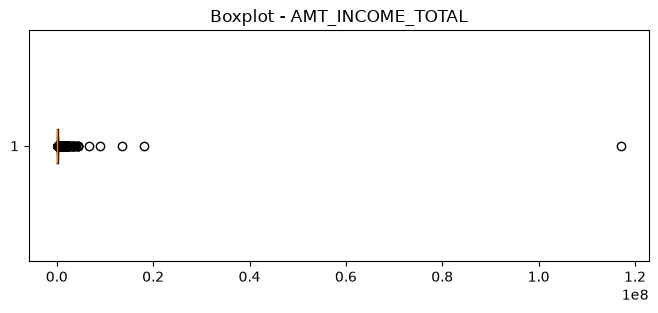

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\3136482645.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(application_reduit[var], vert=False)


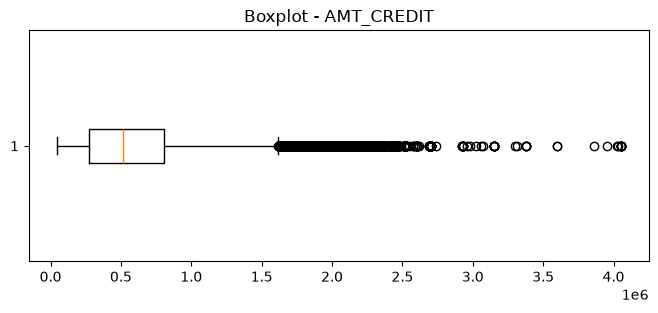

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\3136482645.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(application_reduit[var], vert=False)


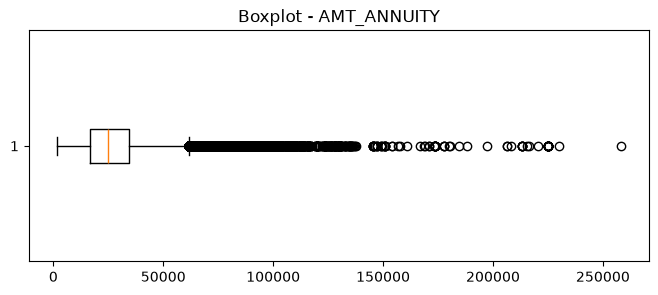

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\3136482645.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(application_reduit[var], vert=False)


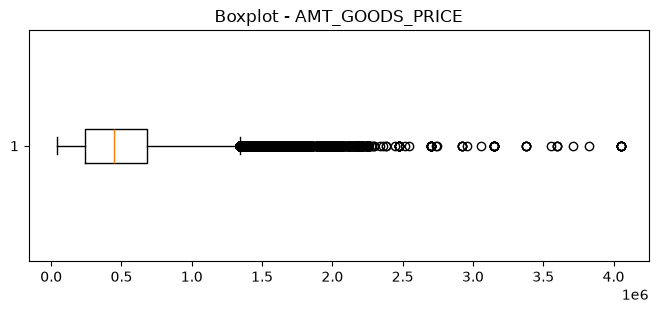

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\3136482645.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(application_reduit[var], vert=False)


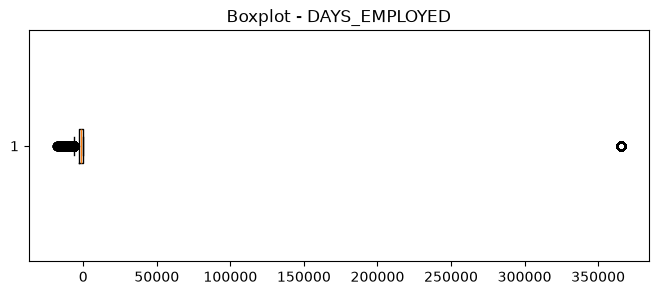

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\3136482645.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(application_reduit[var], vert=False)


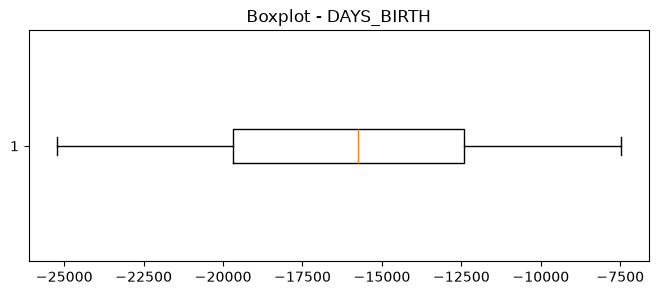

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\3136482645.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(application_reduit[var], vert=False)


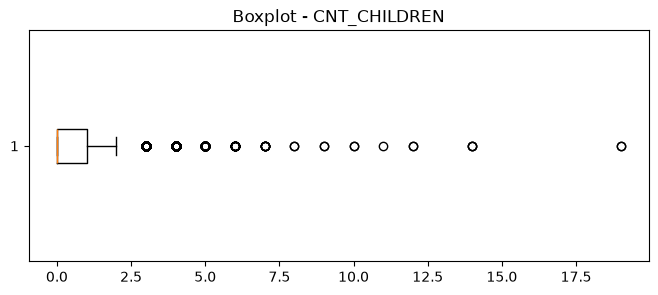


VERIFICATION FINALE
Nombre d'anomalies DAYS_EMPLOYED : 55374
Valeurs manquantes restantes : 0

Nouvelles dimensions : (307511, 65)


In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================
# 1. Variables numériques
# ==========================
variables_numeriques = application_reduit.select_dtypes(include=['int64', 'float64'])

print("="*60)
print("STATISTIQUES DESCRIPTIVES")
print("="*60)
print(variables_numeriques.describe().T)

# ==========================
# 2. Détection des outliers (IQR)
# ==========================
print("\n" + "="*60)
print("DETECTION DES OUTLIERS (Méthode IQR)")
print("="*60)

resultats = []

for col in variables_numeriques.columns:
    Q1 = application_reduit[col].quantile(0.25)
    Q3 = application_reduit[col].quantile(0.75)
    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    nb_outliers = ((application_reduit[col] < borne_inf) |
                   (application_reduit[col] > borne_sup)).sum()

    resultats.append([
        col,
        nb_outliers,
        round(nb_outliers / len(application_reduit) * 100, 2)
    ])

outliers_df = pd.DataFrame(
    resultats,
    columns=["Variable", "Nombre d'outliers", "% d'outliers"]
)

print(outliers_df.sort_values("% d'outliers", ascending=False))

# ==========================
# 3. Boxplots
# ==========================
variables_boxplot = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_EMPLOYED",
    "DAYS_BIRTH",
    "CNT_CHILDREN"
]

for var in variables_boxplot:
    if var in application_reduit.columns:
        plt.figure(figsize=(8,3))
        plt.boxplot(application_reduit[var], vert=False)
        plt.title(f"Boxplot - {var}")
        plt.show()

# ==========================
# 4. Traitement de DAYS_EMPLOYED
# ==========================
if "DAYS_EMPLOYED" in application_reduit.columns:

    application_reduit["DAYS_EMPLOYED_ANOM"] = (
        application_reduit["DAYS_EMPLOYED"] == 365243
    ).astype(int)

    application_reduit["DAYS_EMPLOYED"] = (
        application_reduit["DAYS_EMPLOYED"]
        .replace(365243, np.nan)
    )

    mediane = application_reduit["DAYS_EMPLOYED"].median()

    application_reduit["DAYS_EMPLOYED"] = (
        application_reduit["DAYS_EMPLOYED"]
        .fillna(mediane)
    )

# ==========================
# 5. Transformation logarithmique
# ==========================
if "AMT_INCOME_TOTAL" in application_reduit.columns:

    application_reduit["AMT_INCOME_TOTAL_LOG"] = np.log1p(
        application_reduit["AMT_INCOME_TOTAL"]
    )

# ==========================
# 6. Vérification finale
# ==========================
print("\n" + "="*60)
print("VERIFICATION FINALE")
print("="*60)

if "DAYS_EMPLOYED_ANOM" in application_reduit.columns:
    print("Nombre d'anomalies DAYS_EMPLOYED :",
          application_reduit["DAYS_EMPLOYED_ANOM"].sum())

print("Valeurs manquantes restantes :",
      application_reduit.isnull().sum().sum())

print("\nNouvelles dimensions :", application_reduit.shape)

STATISTIQUES DESCRIPTIVES
                             count           mean            std  \
AMT_INCOME_TOTAL          307511.0  168797.919297  237123.146279   
AMT_CREDIT                307511.0  599025.999706  402490.776996   
AMT_ANNUITY               307511.0   27108.487841   14493.461065   
AMT_GOODS_PRICE           307511.0  538316.294367  369288.982246   
DAYS_BIRTH                307511.0  -16036.995067    4363.988632   
DAYS_EMPLOYED             307511.0   -2251.606131    2136.193492   
DAYS_REGISTRATION         307511.0   -4986.120328    3522.886321   
DAYS_ID_PUBLISH           307511.0   -2994.202373    1509.450419   
DAYS_LAST_PHONE_CHANGE    307511.0    -962.858119     826.807226   
OWN_CAR_AGE               307511.0       4.102026       9.009520   
CNT_CHILDREN              307511.0       0.417052       0.722121   
CNT_FAM_MEMBERS           307511.0       2.152664       0.910679   
EXT_SOURCE_1              307511.0       0.546713       0.183494   
EXT_SOURCE_2          

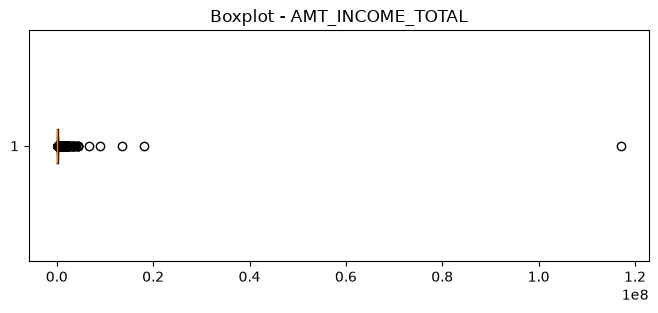

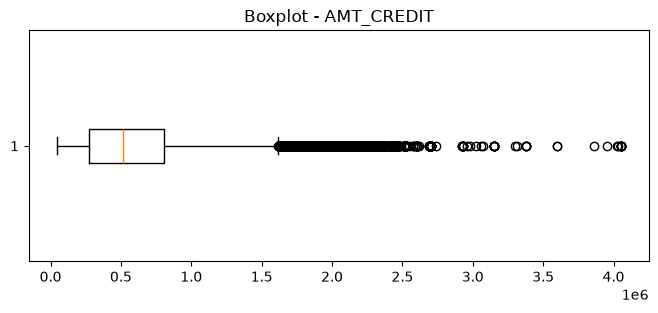

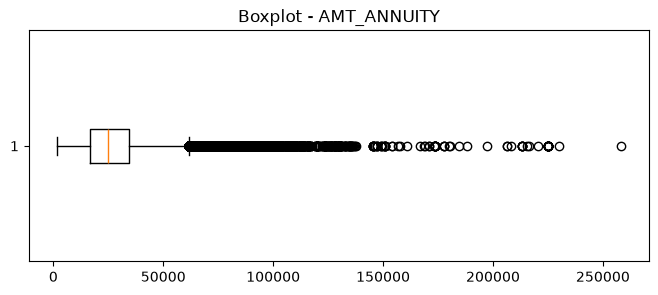

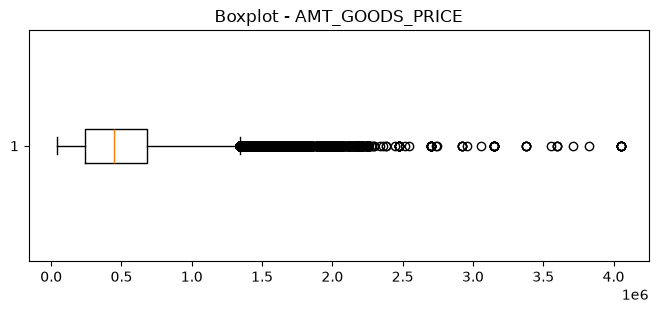

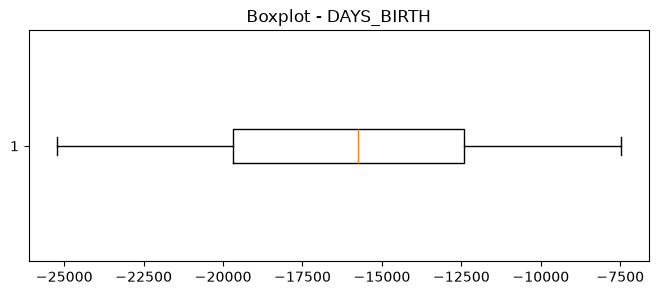

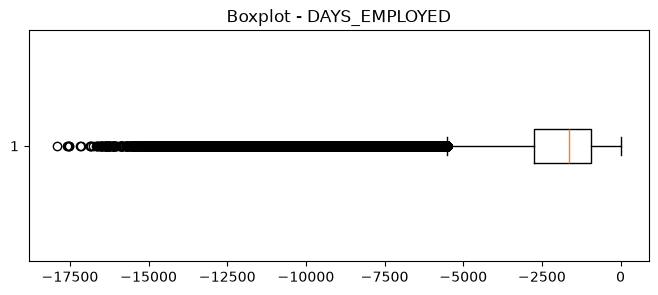

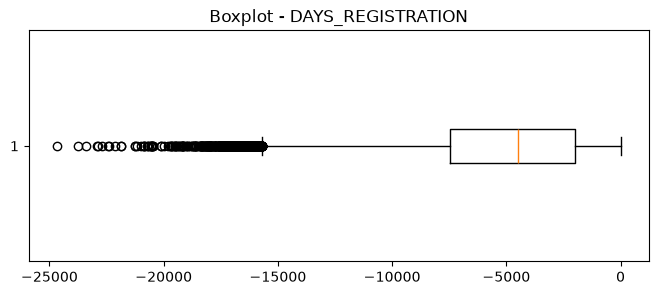

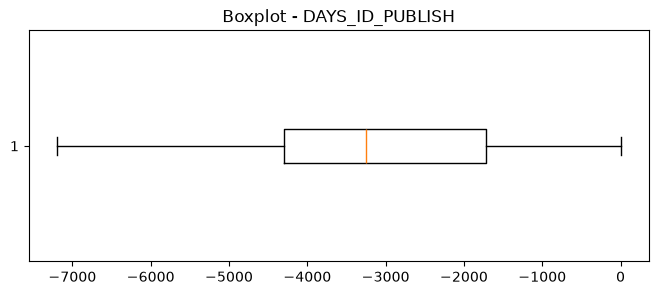

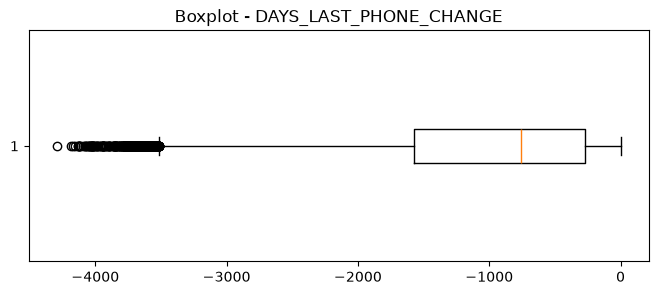

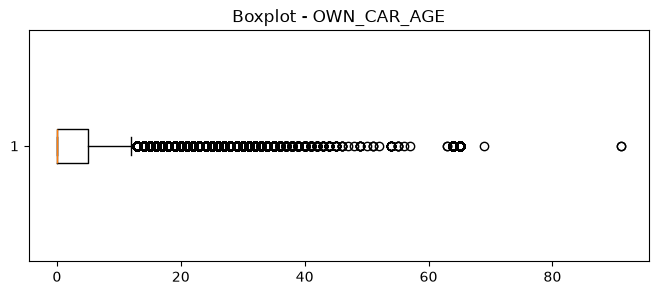

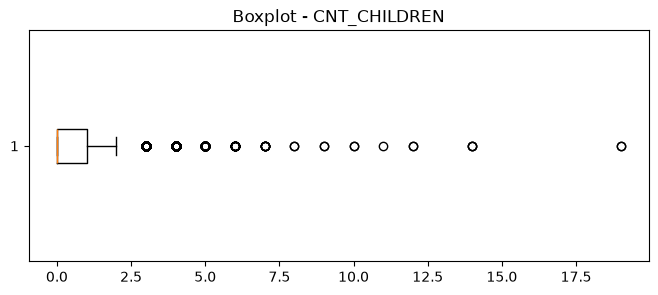

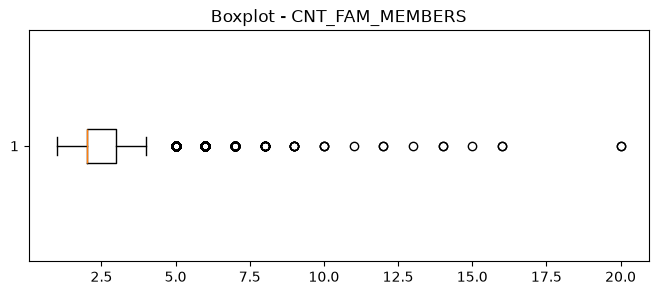

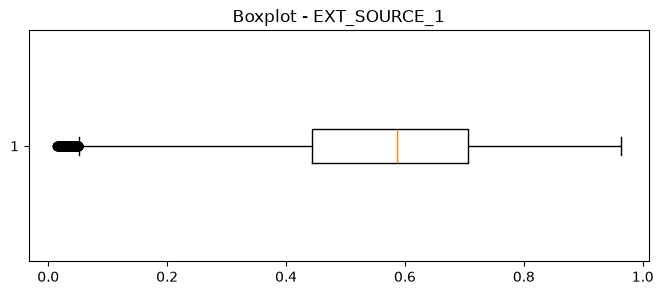

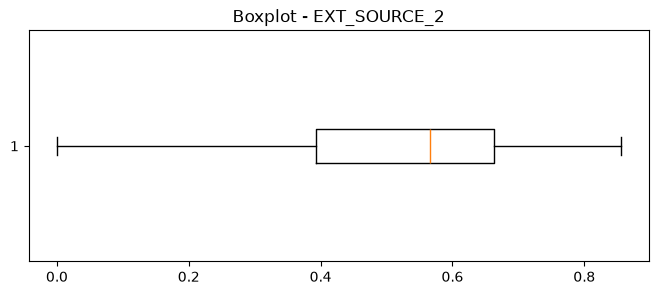

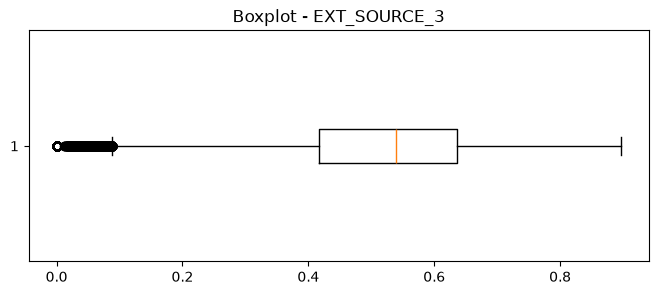

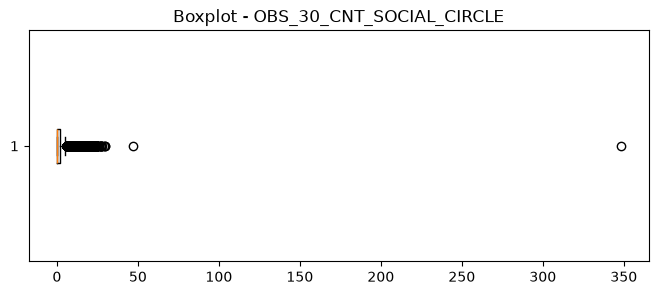

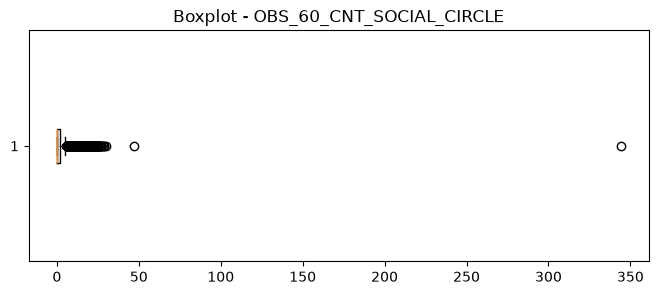

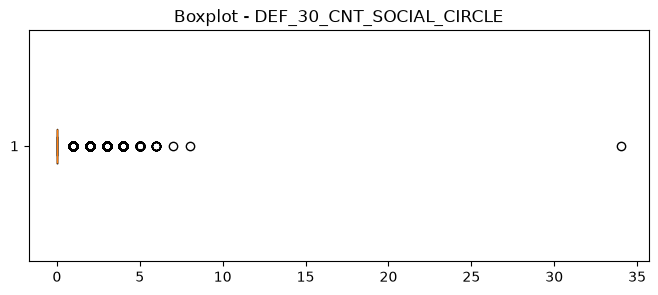

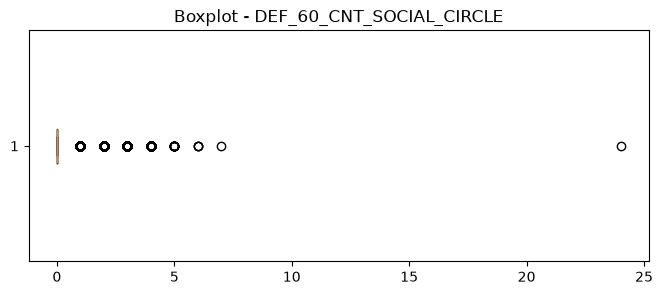


VERIFICATION APRES TRAITEMENT
Valeurs manquantes : 0
Anomalies DAYS_EMPLOYED : 0
Nouvelle dimension : (307511, 65)

Transformation logarithmique créée : True


In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# VARIABLES QUANTITATIVES CONTINUES
# =====================================================

variables_quantitatives = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_REGISTRATION",
    "DAYS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE",
    "OWN_CAR_AGE",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "OBS_30_CNT_SOCIAL_CIRCLE",
    "OBS_60_CNT_SOCIAL_CIRCLE",
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE"
]

# Garder uniquement les variables présentes dans le dataset
variables_quantitatives = [
    col for col in variables_quantitatives
    if col in application_reduit.columns
]

print("="*70)
print("STATISTIQUES DESCRIPTIVES")
print("="*70)

print(application_reduit[variables_quantitatives].describe().T)

# =====================================================
# DETECTION DES OUTLIERS (IQR)
# =====================================================

print("\n" + "="*70)
print("DETECTION DES OUTLIERS")
print("="*70)

resultats = []

for col in variables_quantitatives:

    Q1 = application_reduit[col].quantile(0.25)
    Q3 = application_reduit[col].quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    nb = (
        (application_reduit[col] < borne_inf) |
        (application_reduit[col] > borne_sup)
    ).sum()

    resultats.append([
        col,
        nb,
        round(nb / len(application_reduit) * 100, 2),
        borne_inf,
        borne_sup
    ])

outliers = pd.DataFrame(
    resultats,
    columns=[
        "Variable",
        "Nb_outliers",
        "%_outliers",
        "Borne_inf",
        "Borne_sup"
    ]
)

print(outliers.sort_values("%_outliers", ascending=False))

# =====================================================
# BOXPLOTS
# =====================================================

for col in variables_quantitatives:

    plt.figure(figsize=(8,3))
    plt.boxplot(application_reduit[col], orientation="horizontal")
    plt.title(f"Boxplot - {col}")
    plt.show()

# =====================================================
# TRAITEMENT DE L'ANOMALIE DAYS_EMPLOYED
# =====================================================

if "DAYS_EMPLOYED" in application_reduit.columns:

    application_reduit["DAYS_EMPLOYED_ANOM"] = (
        application_reduit["DAYS_EMPLOYED"] == 365243
    ).astype(int)

    application_reduit["DAYS_EMPLOYED"] = (
        application_reduit["DAYS_EMPLOYED"]
        .replace(365243, np.nan)
    )

    mediane = application_reduit["DAYS_EMPLOYED"].median()

    application_reduit["DAYS_EMPLOYED"] = (
        application_reduit["DAYS_EMPLOYED"]
        .fillna(mediane)
    )

# =====================================================
# TRANSFORMATION LOGARITHMIQUE DU REVENU
# =====================================================

if "AMT_INCOME_TOTAL" in application_reduit.columns:

    application_reduit["AMT_INCOME_TOTAL_LOG"] = np.log1p(
        application_reduit["AMT_INCOME_TOTAL"]
    )

# =====================================================
# VERIFICATIONS FINALES
# =====================================================

print("\n" + "="*70)
print("VERIFICATION APRES TRAITEMENT")
print("="*70)

print("Valeurs manquantes :", application_reduit.isnull().sum().sum())

if "DAYS_EMPLOYED_ANOM" in application_reduit.columns:
    print("Anomalies DAYS_EMPLOYED :", application_reduit["DAYS_EMPLOYED_ANOM"].sum())

print("Nouvelle dimension :", application_reduit.shape)

print("\nTransformation logarithmique créée :",
      "AMT_INCOME_TOTAL_LOG" in application_reduit.columns)

In [106]:
application_reduit.shape


(307511, 65)

In [107]:
# ======================================
# PREPARATION ACP
# ======================================

import pandas as pd
import numpy as np

# Copie du dataset final
X_acp = application_reduit.copy()

# Retirer identifiant et cible
X_acp = X_acp.drop(
    columns=['SK_ID_CURR', 'TARGET'],
    errors='ignore'
)

print("Dimension avant sélection quantitative :", X_acp.shape)


# Garder uniquement les variables numériques
X_acp_quant = X_acp.select_dtypes(
    include=['int64','float64']
)


print("Dimension après sélection quantitative :", X_acp_quant.shape)

print("\nTypes des variables :")
print(X_acp_quant.dtypes.value_counts())

print("\nValeurs manquantes :")
print(X_acp_quant.isnull().sum().sum())


Dimension avant sélection quantitative : (307511, 63)
Dimension après sélection quantitative : (307511, 48)

Types des variables :
int64      24
float64    24
Name: count, dtype: int64

Valeurs manquantes :
0


In [108]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_acp_quant)

print(X_scaled.shape)

(307511, 48)


In [109]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

(307511, 48)


In [110]:
# Variance expliquée par chaque composante
variance_expliquee = pca.explained_variance_ratio_

# Variance cumulée
variance_cumulee = np.cumsum(variance_expliquee)


# Affichage des seuils
for seuil in [0.80, 0.85, 0.90, 0.95]:

    nombre_composantes = np.argmax(
        variance_cumulee >= seuil
    ) + 1

    print(
        f"{seuil*100}% de variance expliquée -> {nombre_composantes} composantes"
    )

80.0% de variance expliquée -> 24 composantes
85.0% de variance expliquée -> 27 composantes
90.0% de variance expliquée -> 30 composantes
95.0% de variance expliquée -> 34 composantes


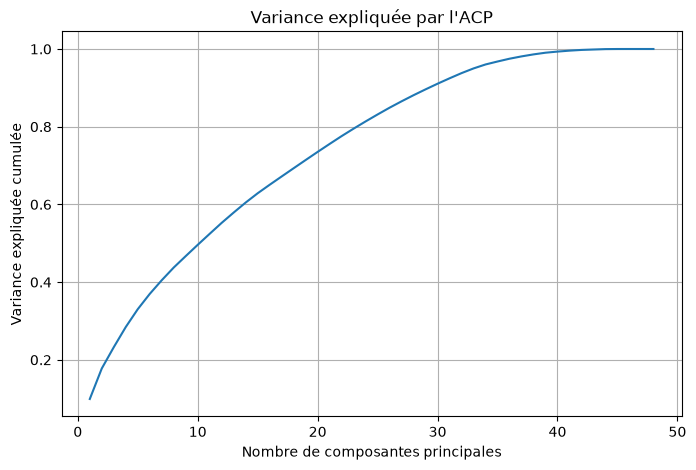

In [111]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(variance_cumulee)+1),
    variance_cumulee
)

plt.xlabel("Nombre de composantes principales")
plt.ylabel("Variance expliquée cumulée")
plt.title("Variance expliquée par l'ACP")

plt.grid()

plt.show()

In [112]:
from sklearn.decomposition import PCA


# ACP finale avec 90% de variance conservée
pca_final = PCA(n_components=30)

X_pca_final = pca_final.fit_transform(X_scaled)


print("Nouvelle dimension après ACP :", X_pca_final.shape)


print(
    "Variance conservée :",
    pca_final.explained_variance_ratio_.sum()
)

Nouvelle dimension après ACP : (307511, 30)
Variance conservée : 0.9106670607542414


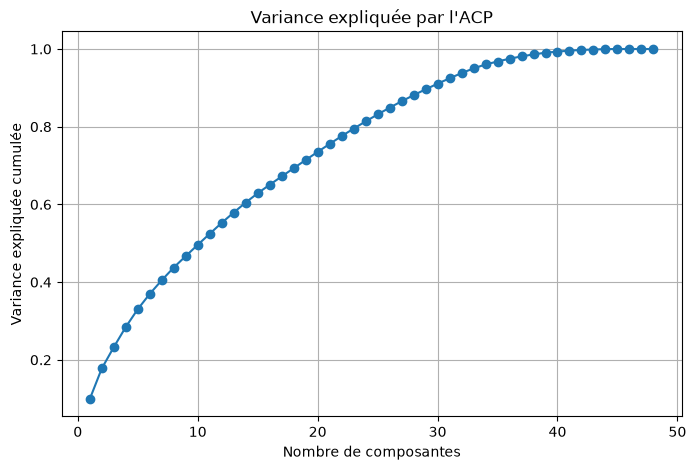

In [113]:
import matplotlib.pyplot as plt
import numpy as np

variance_cumulee = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8,5))

plt.plot(
    range(1,len(variance_cumulee)+1),
    variance_cumulee,
    marker='o'
)

plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("Variance expliquée par l'ACP")

plt.grid()

plt.show()

In [114]:
# ======================================
# ACP FINALE (90% VARIANCE)
# ======================================

from sklearn.decomposition import PCA

pca_final = PCA(n_components=30)

X_pca_final = pca_final.fit_transform(X_scaled)


print("Dimension après ACP :", X_pca_final.shape)

print(
    "Variance conservée :",
    pca_final.explained_variance_ratio_.sum()
)



# ======================================
# CONTRIBUTION DES VARIABLES
# ======================================

loadings = pd.DataFrame(
    pca_final.components_.T,
    columns=[
        f"PC{i+1}" 
        for i in range(pca_final.n_components_)
    ],
    index=X_acp_quant.columns
)


print("Variables importantes PC1")
print(
    loadings["PC1"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
)


print("\nVariables importantes PC2")
print(
    loadings["PC2"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

Dimension après ACP : (307511, 30)
Variance conservée : 0.9106670607542414
Variables importantes PC1
DAYS_BIRTH                 0.401887
age_years                  0.401840
FLAG_EMP_PHONE             0.345386
EXT_SOURCE_1               0.339273
FLAG_DOCUMENT_6            0.262674
REG_CITY_NOT_WORK_CITY     0.213736
CNT_CHILDREN               0.207742
CNT_FAM_MEMBERS            0.196982
DAYS_REGISTRATION          0.184297
LIVE_CITY_NOT_WORK_CITY    0.171808
Name: PC1, dtype: float64

Variables importantes PC2
AMT_GOODS_PRICE                0.383509
AMT_CREDIT                     0.380690
AMT_ANNUITY                    0.368100
AMT_INCOME_TOTAL_LOG           0.321371
REGION_RATING_CLIENT_W_CITY    0.304557
REGION_RATING_CLIENT           0.301069
REGION_POPULATION_RELATIVE     0.240413
EXT_SOURCE_2                   0.210935
AMT_INCOME_TOTAL               0.164294
EXT_SOURCE_1                   0.132522
Name: PC2, dtype: float64


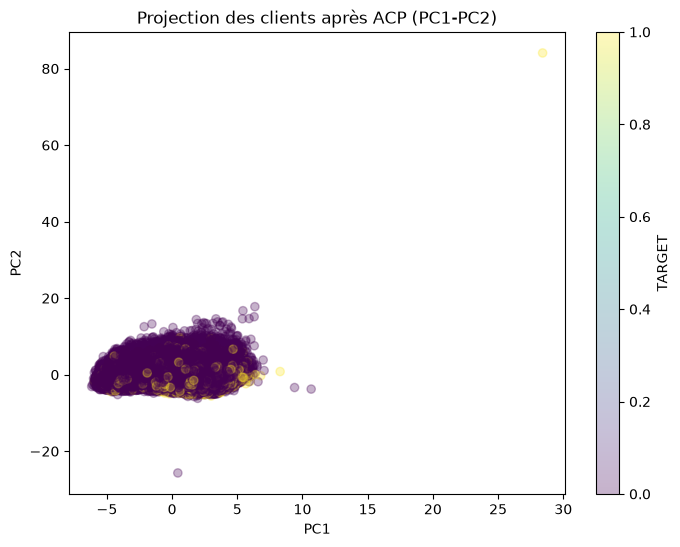

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    X_pca_final[:,0],
    X_pca_final[:,1],
    c=application_reduit['TARGET'],
    alpha=0.3
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Projection des clients après ACP (PC1-PC2)")

plt.colorbar(label="TARGET")

plt.show()

2 eme etape : analyse des valeurs quasiconstanntes : 

CATEGORIE CONTACT 


jusqu'a ici fin de la nouvelle essaie 

---------------------------------------------------------------------------------------------------------------

ENCODAGE 


In [116]:
application_reduit.select_dtypes(include='object').columns

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\612058418.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  application_reduit.select_dtypes(include='object').columns


Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE',
       'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'HOUSETYPE_MODE',
       'WALLSMATERIAL_MODE'],
      dtype='str')

In [117]:
# ======================================
# ENCODAGE DES VARIABLES QUALITATIVES
# ======================================

import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Copie du dataset après traitement anomalies/outliers
application_encode = application_reduit.copy()


# -------------------------------
# 1) Variables binaires
# -------------------------------

colonnes_binaires = [
    'NAME_CONTRACT_TYPE',
    'CODE_GENDER',
    'FLAG_OWN_CAR',
    'FLAG_OWN_REALTY'
]

le = LabelEncoder()

for col in colonnes_binaires:
    application_encode[col] = le.fit_transform(
        application_encode[col]
    )


# -------------------------------
# 2) Variables multi-catégories
# -------------------------------

colonnes_multicategories = [
    'NAME_TYPE_SUITE',
    'NAME_INCOME_TYPE',
    'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS',
    'NAME_HOUSING_TYPE',
    'OCCUPATION_TYPE',
    'WEEKDAY_APPR_PROCESS_START',
    'ORGANIZATION_TYPE',
    'HOUSETYPE_MODE',
    'WALLSMATERIAL_MODE'
]


application_encode = pd.get_dummies(
    application_encode,
    columns=colonnes_multicategories,
    drop_first=True,
    dtype=int
)


# -------------------------------
# Vérifications
# -------------------------------

print("Dimension après encodage :", application_encode.shape)

print("\nVariables qualitatives restantes :")
print(application_encode.select_dtypes(include='object').columns)

print("\nValeurs manquantes restantes :")
print(application_encode.isnull().sum().sum())

Dimension après encodage : (307511, 173)

Variables qualitatives restantes :
Index([], dtype='str')

Valeurs manquantes restantes :
0


In [118]:
X = application_encode.drop(
    columns=['TARGET','SK_ID_CURR'],
    errors='ignore'
)

y = application_encode['TARGET']

In [119]:
application_encode.dtypes.value_counts()

int64       148
float64      24
category      1
Name: count, dtype: int64

In [120]:
application_encode['age_tranche'].value_counts()

age_tranche
30-40    83117
40-50    74401
50-60    67819
20-30    52806
60-70    29368
Name: count, dtype: int64

In [121]:
# Préparation finale pour ACP après encodage

X_acp_encode = application_encode.drop(
    columns=['TARGET', 'SK_ID_CURR', 'age_tranche'],
    errors='ignore'
)

print("Dimension avant ACP :", X_acp_encode.shape)

print("\nTypes des variables :")
print(X_acp_encode.dtypes.value_counts())

print("\nValeurs manquantes :")
print(X_acp_encode.isnull().sum().sum())

Dimension avant ACP : (307511, 170)

Types des variables :
int64      146
float64     24
Name: count, dtype: int64

Valeurs manquantes :
0


In [122]:
ordre_age = {
    '20-30':1,
    '30-40':2,
    '40-50':3,
    '50-60':4,
    '60-70':5
}

application_encode['age_tranche'] = application_encode['age_tranche'].map(ordre_age)

Dimension avant ACP : (307511, 171)

Types :
int64       146
float64      24
category      1
Name: count, dtype: int64

Valeurs manquantes :
0
80.0% variance expliquée -> 103 composantes
85.0% variance expliquée -> 112 composantes
90.0% variance expliquée -> 121 composantes
95.0% variance expliquée -> 132 composantes


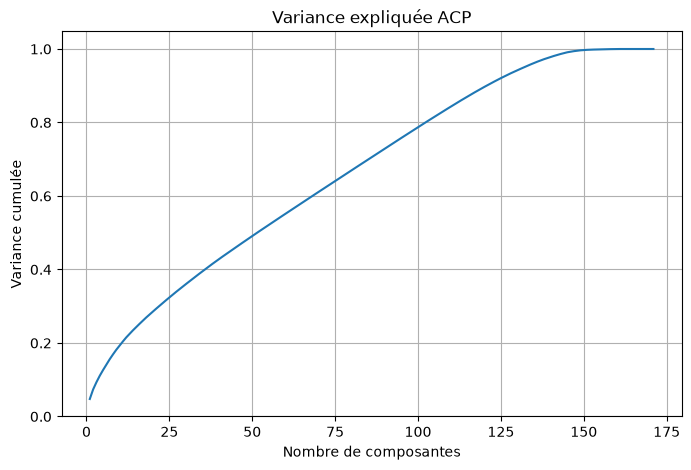

In [123]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt


# Copie finale
X = application_encode.copy()


# Retirer cible et identifiant
X = X.drop(
    columns=['SK_ID_CURR','TARGET'],
    errors='ignore'
)


print("Dimension avant ACP :", X.shape)


# Vérification
print("\nTypes :")
print(X.dtypes.value_counts())


print("\nValeurs manquantes :")
print(X.isnull().sum().sum())


# Standardisation
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ACP complète
pca = PCA()

X_pca = pca.fit_transform(X_scaled)


# Variance cumulée
variance_cumulee = np.cumsum(
    pca.explained_variance_ratio_
)


for seuil in [0.80,0.85,0.90,0.95]:

    nb = np.argmax(
        variance_cumulee >= seuil
    ) + 1

    print(
        f"{seuil*100}% variance expliquée -> {nb} composantes"
    )


# Courbe variance
plt.figure(figsize=(8,5))

plt.plot(
    range(1,len(variance_cumulee)+1),
    variance_cumulee
)

plt.xlabel("Nombre de composantes")
plt.ylabel("Variance cumulée")
plt.title("Variance expliquée ACP")

plt.grid()
plt.show()

In [124]:
from sklearn.decomposition import PCA

pca_final = PCA(n_components=121)

X_pca_final = pca_final.fit_transform(X_scaled)

print(X_pca_final.shape)

print(
    "Variance conservée :",
    pca_final.explained_variance_ratio_.sum()
)

(307511, 121)
Variance conservée : 0.901762480682051


In [125]:
loadings = pd.DataFrame(
    pca_final.components_.T,
    columns=[f"PC{i+1}" for i in range(121)],
    index=X.columns
)

In [126]:
loadings["PC1"].abs().sort_values(ascending=False).head(10)

ORGANIZATION_TYPE_XNA         0.308660
NAME_INCOME_TYPE_Pensioner    0.308652
FLAG_EMP_PHONE                0.308628
DAYS_BIRTH                    0.299133
age_years                     0.299111
age_tranche                   0.293557
EXT_SOURCE_1                  0.242052
OCCUPATION_TYPE_Unknown       0.235576
FLAG_DOCUMENT_6               0.212299
NAME_INCOME_TYPE_Working      0.154990
Name: PC1, dtype: float64

In [127]:
loadings["PC2"].abs().sort_values(ascending=False).head(10)

AMT_GOODS_PRICE                  0.309903
AMT_CREDIT                       0.305927
AMT_ANNUITY                      0.302694
AMT_INCOME_TOTAL_LOG             0.298400
REGION_RATING_CLIENT_W_CITY      0.247104
REGION_RATING_CLIENT             0.240629
REGION_POPULATION_RELATIVE       0.200416
EXT_SOURCE_2                     0.192032
HOUSETYPE_MODE_block of flats    0.190727
WALLSMATERIAL_MODE_Inconnu       0.189874
Name: PC2, dtype: float64

In [128]:
loadings["PC3"].abs().sort_values(ascending=False).head(10)

WALLSMATERIAL_MODE_Inconnu                 0.285839
HOUSETYPE_MODE_block of flats              0.282240
FLAG_OWN_CAR                               0.278480
OWN_CAR_AGE_MISSING                        0.278476
NAME_FAMILY_STATUS_Married                 0.259663
OWN_CAR_AGE                                0.220340
NAME_FAMILY_STATUS_Single / not married    0.214210
CNT_FAM_MEMBERS                            0.213825
CODE_GENDER                                0.168059
WALLSMATERIAL_MODE_Panel                   0.158471
Name: PC3, dtype: float64

--------------------------------------------------------------------------------------------

In [129]:
application_reduit.select_dtypes(include='object').columns


C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\4108147553.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  application_reduit.select_dtypes(include='object').columns


Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE',
       'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'HOUSETYPE_MODE',
       'WALLSMATERIAL_MODE'],
      dtype='str')

encodage pour les variables binaires ; 

In [130]:
import sys
print(sys.executable)

c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Scripts\python.exe


In [131]:
from sklearn.preprocessing import LabelEncoder

In [132]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

colonnes_binaires = [
    'NAME_CONTRACT_TYPE',
    'CODE_GENDER',
    'FLAG_OWN_CAR',
    'FLAG_OWN_REALTY'
]

for col in colonnes_binaires:
    application_reduit[col] = le.fit_transform(application_reduit[col])

In [133]:
colonnes_multicategories = [
    'NAME_TYPE_SUITE',
    'NAME_INCOME_TYPE',
    'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS',
    'NAME_HOUSING_TYPE',
    'OCCUPATION_TYPE',
    'WEEKDAY_APPR_PROCESS_START',
    'ORGANIZATION_TYPE'
]

application_encode = pd.get_dummies(
    application_reduit,
    columns=colonnes_multicategories,
    drop_first=True,
    dtype=int
)

In [134]:
application_encode.select_dtypes(include='object').columns

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\1142717157.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  application_encode.select_dtypes(include='object').columns


Index(['HOUSETYPE_MODE', 'WALLSMATERIAL_MODE'], dtype='str')

In [135]:
application_encode.select_dtypes(include='object').columns

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\1142717157.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  application_encode.select_dtypes(include='object').columns


Index(['HOUSETYPE_MODE', 'WALLSMATERIAL_MODE'], dtype='str')

In [136]:
application_encode.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'HOUSETYPE_MODE',
 'WALLSMATERIAL_MODE',
 'OBS_30_CNT_SOCIAL_CIRCLE',
 'DEF_30_CNT_SOCIAL_CIRCLE',
 'OBS_60_CNT_SOCIAL_CIRCLE',
 'DEF_60_CNT_SOCIAL_CIRCLE',
 'DAYS_LAST_PHONE_CHANGE',
 'FLAG_DOCUMENT_3',
 'FLAG_DOCUMENT_5',
 'FLAG_DOCUMENT_6',
 'FLAG_DOCUMENT_8',


In [137]:
# Charger le fichier brut, non modifié, pour reproduire le diagnostic "avant traitement"
application_brute_verif = pd.read_csv(r"C:\Users\Asus\OneDrive\Bureau\FinTech\data\raw\application_train.csv")

# Reconstruire age_tranche sur ce fichier brut
application_brute_verif['age_years'] = (-application_brute_verif['DAYS_BIRTH'] / 365).astype(int)
application_brute_verif['age_tranche'] = pd.cut(
    application_brute_verif['age_years'],
    bins=[20, 30, 40, 50, 60, 70],
    labels=['20-30', '30-40', '40-50', '50-60', '60-70'],
    include_lowest=True
)

print("=== 1. EXT_SOURCE_1 × tranche d'âge (médiane, AVANT traitement) ===")
print(application_brute_verif.groupby('age_tranche', observed=True)['EXT_SOURCE_1'].median())

print("\n=== 2. EXT_SOURCE_3 × tranche d'âge (médiane, AVANT traitement) ===")
print(application_brute_verif.groupby('age_tranche', observed=True)['EXT_SOURCE_3'].median())

print("\n=== 3. OCCUPATION_TYPE × NAME_INCOME_TYPE (% manquant, AVANT traitement) ===")
print(application_brute_verif.groupby('NAME_INCOME_TYPE')['OCCUPATION_TYPE'].apply(lambda x: x.isnull().mean()*100))

print("\n=== 4. OWN_CAR_AGE × FLAG_OWN_CAR (% manquant, AVANT traitement) ===")
print(application_brute_verif.groupby('FLAG_OWN_CAR')['OWN_CAR_AGE'].apply(lambda x: x.isnull().mean()*100))

print("\n=== 5. HOUSETYPE_MODE × TARGET (taux de défaut, AVANT traitement) ===")
print(application_brute_verif.groupby('HOUSETYPE_MODE', dropna=False)['TARGET'].mean())

print("\n=== 6. WALLSMATERIAL_MODE × TARGET (taux de défaut, AVANT traitement) ===")
print(application_brute_verif.groupby('WALLSMATERIAL_MODE', dropna=False)['TARGET'].mean())

C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\1217680067.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  application_brute_verif['age_years'] = (-application_brute_verif['DAYS_BIRTH'] / 365).astype(int)
C:\Users\Asus\AppData\Local\Temp\ipykernel_20524\1217680067.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  application_brute_verif['age_tranche'] = pd.cut(


=== 1. EXT_SOURCE_1 × tranche d'âge (médiane, AVANT traitement) ===
age_tranche
20-30    0.313037
30-40    0.448080
40-50    0.586095
50-60    0.705385
60-70    0.778177
Name: EXT_SOURCE_1, dtype: float64

=== 2. EXT_SOURCE_3 × tranche d'âge (médiane, AVANT traitement) ===
age_tranche
20-30    0.440058
30-40    0.519097
40-50    0.553165
50-60    0.567379
60-70    0.612704
Name: EXT_SOURCE_3, dtype: float64

=== 3. OCCUPATION_TYPE × NAME_INCOME_TYPE (% manquant, AVANT traitement) ===
NAME_INCOME_TYPE
Businessman              20.000000
Commercial associate     17.170504
Maternity leave          20.000000
Pensioner                99.990969
State servant            17.449201
Student                  27.777778
Unemployed              100.000000
Working                  15.695265
Name: OCCUPATION_TYPE, dtype: float64

=== 4. OWN_CAR_AGE × FLAG_OWN_CAR (% manquant, AVANT traitement) ===
FLAG_OWN_CAR
N    100.000000
Y      0.004781
Name: OWN_CAR_AGE, dtype: float64

=== 5. HOUSETYPE_MODE × TA

In [138]:
application_train.shape
application_train.info()
application_train.head()
application_train.isnull().sum().sort_values(ascending=False).head(20)

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 286.2 MB


COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
FLOORSMIN_MEDI              208642
YEARS_BUILD_AVG             204488
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
OWN_CAR_AGE                 202929
LANDAREA_MEDI               182590
LANDAREA_AVG                182590
LANDAREA_MODE               182590
dtype: int64

In [139]:
application_encode.to_csv(
    "data/processed/application_train_encode.csv",
    index=False
)

print("Sauvegardé :", application_encode.shape)

Sauvegardé : (307511, 165)


In [5]:
for name, obj in list(globals().items()):
    if hasattr(obj, "shape") and hasattr(obj, "columns"):
        print(f"{name}: {obj.shape}")

In [6]:
%whos DataFrame

No variables match your requested type.
